✅ Simulation 02 completed successfully!
📁 High-resolution figure saved at: figures/sim02_photon_statistics_mandel_q.png


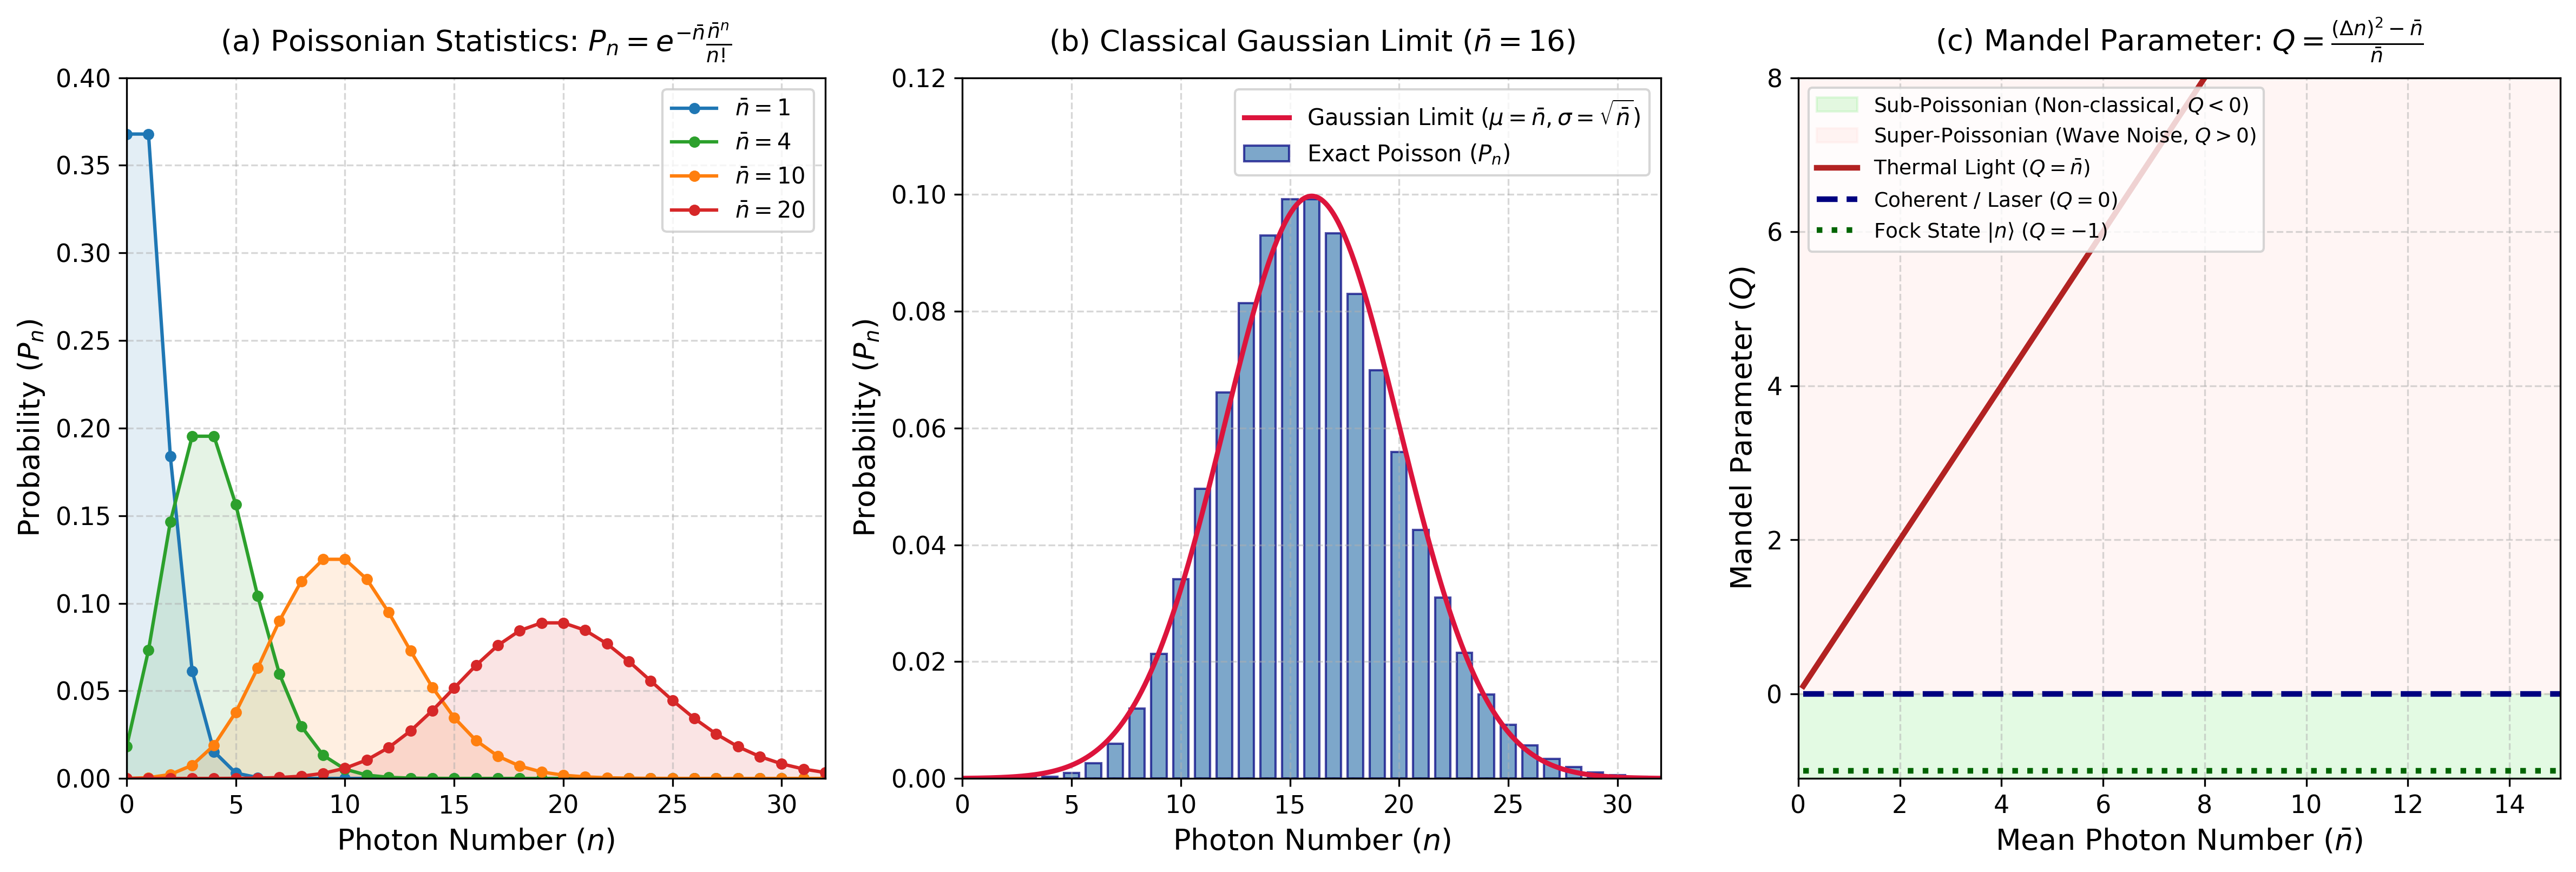

In [2]:
"""
===============================================================================
Computational Quantum Optics: Gerry & Knight Simulations
Chapter 03: Coherent States of Light
Simulation 02: Poissonian Photon Statistics & Mandel Q-Parameter
===============================================================================

Reference:
    "Introductory Quantum Optics", Christopher C. Gerry & Sir Peter L. Knight,
    Chapter 3, Section 3.2: Properties of Coherent States.

Description:
    Simulates the photon number probability distribution P_n for coherent states
    with varying mean photon numbers, confirms the Poissonian shot-noise limit 
    (var(n) = <n>), illustrates the emergence of the continuous Gaussian distribution
    at large n_bar, and computes the Mandel Q-parameter to benchmark coherent light 
    against non-classical Fock states (sub-Poissonian) and thermal light (super-Poissonian).
"""

import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson, norm

# -----------------------------------------------------------------------------
# 1. Aesthetics & Plot Setup
# -----------------------------------------------------------------------------
plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 13,
    'axes.titlesize': 13,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 10,
    'figure.titlesize': 15,
    'text.usetex': False  # Fully compatible with Kaggle without LaTeX dependencies
})

# -----------------------------------------------------------------------------
# 2. Physics & Numerical Computations
# -----------------------------------------------------------------------------
# (a) Multi-Poisson distributions for varying intensities
n_bars = [1.0, 4.0, 10.0, 20.0]
colors_a = ['#1f77b4', '#2ca02c', '#ff7f0e', '#d62728']
max_n_a = 35
n_discrete_a = np.arange(0, max_n_a + 1)

# (b) Gaussian limit comparison at n_bar = 16
n_bar_comp = 16.0
max_n_b = 35
n_discrete_b = np.arange(0, max_n_b + 1)
p_poisson_b = poisson.pmf(n_discrete_b, mu=n_bar_comp)

# Continuous Gaussian approximation: mu = n_bar, sigma = sqrt(n_bar)
n_cont_b = np.linspace(0, max_n_b, 500)
p_gaussian_b = norm.pdf(n_cont_b, loc=n_bar_comp, scale=np.sqrt(n_bar_comp))

# (c) Mandel Q-parameter vs. Mean Photon Number
n_bar_range = np.linspace(0.1, 15.0, 300)

# Mandel Q definitions:
# Coherent state: (Delta n)^2 = n_bar  ==> Q = 0
q_coherent = np.zeros_like(n_bar_range)

# Fock state |n>: (Delta n)^2 = 0     ==> Q = -1
q_fock = -1.0 * np.ones_like(n_bar_range)

# Thermal state: (Delta n)^2 = n_bar + n_bar^2 ==> Q = n_bar
q_thermal = n_bar_range

# -----------------------------------------------------------------------------
# 3. Figure Generation (Multi-Panel Layout)
# -----------------------------------------------------------------------------
fig = plt.figure(figsize=(16, 5.5), dpi=300)
gs = fig.add_gridspec(1, 3, width_ratios=[1.1, 1.1, 1.2])

# --- Subplot (a): Poisson Distributions across Intensities ---
ax1 = fig.add_subplot(gs[0, 0])
for nb, col in zip(n_bars, colors_a):
    p_n = poisson.pmf(n_discrete_a, mu=nb)
    ax1.plot(n_discrete_a, p_n, marker='o', markersize=4, lw=1.5, color=col, 
             label=rf'$\bar{{n}} = {int(nb)}$')
    ax1.fill_between(n_discrete_a, p_n, alpha=0.12, color=col)

ax1.set_title(r'(a) Poissonian Statistics: $P_n = e^{-\bar{n}} \frac{\bar{n}^n}{n!}$', pad=12)
ax1.set_xlabel(r'Photon Number ($n$)')
ax1.set_ylabel(r'Probability ($P_n$)')
ax1.set_xlim([0, 32])
ax1.set_ylim([0, 0.4])
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper right', frameon=True)

# --- Subplot (b): Emergence of Gaussian Distribution ---
ax2 = fig.add_subplot(gs[0, 1])
ax2.bar(n_discrete_b, p_poisson_b, width=0.7, color='steelblue', alpha=0.7, 
        edgecolor='navy', label=r'Exact Poisson ($P_n$)')
ax2.plot(n_cont_b, p_gaussian_b, color='crimson', lw=2.2, linestyle='-',
         label=r'Gaussian Limit ($\mu = \bar{n}, \sigma = \sqrt{\bar{n}}$)')

ax2.set_title(rf'(b) Classical Gaussian Limit ($\bar{{n}} = {int(n_bar_comp)}$)', pad=12)
ax2.set_xlabel(r'Photon Number ($n$)')
ax2.set_ylabel(r'Probability ($P_n$)')
ax2.set_xlim([0, 32])
ax2.set_ylim([0, 0.12])
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right', frameon=True)

# --- Subplot (c): Mandel Q-Parameter & State Classification ---
ax3 = fig.add_subplot(gs[0, 2])

# Background shading for quantum vs classical domains
ax3.axhspan(-1.1, 0.0, color='lightgreen', alpha=0.25, label=r'Sub-Poissonian (Non-classical, $Q < 0$)')
ax3.axhspan(0.0, 15.0, color='mistyrose', alpha=0.35, label=r'Super-Poissonian (Wave Noise, $Q > 0$)')

# Curves for states
ax3.plot(n_bar_range, q_thermal, color='firebrick', lw=2.5, label=r'Thermal Light ($Q = \bar{n}$)')
ax3.plot(n_bar_range, q_coherent, color='navy', lw=2.5, linestyle='--', label=r'Coherent / Laser ($Q = 0$)')
ax3.plot(n_bar_range, q_fock, color='darkgreen', lw=2.5, linestyle=':', label=r'Fock State $|n\rangle$ ($Q = -1$)')

ax3.set_title(r'(c) Mandel Parameter: $Q = \frac{(\Delta n)^2 - \bar{n}}{\bar{n}}$', pad=12)
ax3.set_xlabel(r'Mean Photon Number ($\bar{n}$)')
ax3.set_ylabel(r'Mandel Parameter ($Q$)')
ax3.set_xlim([0, 15])
ax3.set_ylim([-1.1, 8.0])
ax3.grid(True, linestyle='--', alpha=0.5)
ax3.legend(loc='upper left', frameon=True, fontsize=9)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 4. Save and Export
# -----------------------------------------------------------------------------
os.makedirs("figures", exist_ok=True)
output_path = os.path.join("figures", "sim02_photon_statistics_mandel_q.png")
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"✅ Simulation 02 completed successfully!")
print(f"📁 High-resolution figure saved at: {output_path}")

plt.show()